# Runner Notebook 2

In [1]:
library(ggplot2)

In [2]:
project_root <- if (file.exists("R/part2.R")) "." else ".."

read_height_gwas <- function(file = "data/raw/Height.gwas.txt.gz") {
  gwas <- read.delim(file)

  # Keep SNPs with stronger evidence of association with height and reliable imputation quality
  keep <- gwas$P <= 0.001 & gwas$INFO > 0.8

  candidates <- gwas[
    which(keep),
    c("CHR", "BP", "SNP", "A1", "A2", "P", "OR")
  ]
  candidates$weight <- log(candidates$OR)

  candidates
}

In [3]:
read_height_bim <- function(file) {
  read.table(
    file,
    col.names = c("CHR", "SNP", "CM", "BP", "A1", "A2"),
    colClasses = c("integer", "character", "NULL", "integer",
                   "character", "character")
  )
}

In [4]:
match_height_positions <- function(gwas, reference) {
  positions <- list(gwas = gwas$BP, reference = reference$BP)
  unique_positions <- lapply(positions, function(x) {
    x[!duplicated(x) & !duplicated(x, fromLast = TRUE)]
  })
  shared <- Reduce(intersect, unique_positions)
  gwas_rows <- match(shared, positions$gwas)
  reference_rows <- match(shared, positions$reference)

  data.frame(
    gwas[gwas_rows, ],
    reference_row = reference_rows,
    reference_snp = reference$SNP[reference_rows],
    reference_a1 = reference$A1[reference_rows],
    reference_a2 = reference$A2[reference_rows]
  )
}

In [5]:
align_height_alleles <- function(matches) {
  reference_matches <-
    (matches$reference_a1 == matches$A1 & matches$reference_a2 == matches$A2) |
    (matches$reference_a1 == matches$A2 & matches$reference_a2 == matches$A1)
  matches[which(reference_matches), , drop = FALSE]
}

In [6]:
clump_height_chromosome <- function(variants, chromosome, reference_prefix,
                                    held_out_sample, output_dir, plink_executable) {
  output_prefix <- file.path(output_dir, paste0("chr", chromosome))
  clump_input <- paste0(output_prefix, "_clump_input.tsv")
  remove_file <- paste0(output_prefix, "_holdout.tsv")

  write.table(
    data.frame(ID = variants$reference_snp, P = variants$P),
    clump_input,
    sep = "\t", quote = FALSE, row.names = FALSE
  )
  write.table(
    held_out_sample, remove_file, sep = "\t", quote = FALSE,
    row.names = FALSE, col.names = FALSE
  )

  status <- system2(plink_executable, c(
    "--bfile", shQuote(reference_prefix),
    "--remove", shQuote(remove_file),
    "--clump", shQuote(clump_input),
    "--clump-p1", "0.001",
    "--clump-r2", "0.1",
    "--clump-kb", "250",
    "--out", shQuote(output_prefix)
  ))

  if (status != 0) {
    stop("PLINK clumping failed on chromosome ", chromosome)
  }

  clump_file <- paste0(output_prefix, ".clumps")
  if (!file.exists(clump_file)) {
    return(variants[FALSE, , drop = FALSE])
  }
  clumps <- read.delim(clump_file)
  lead_rows <- match(clumps$ID, variants$reference_snp)
  variants[lead_rows, , drop = FALSE]
}

In [7]:
score_height_chromosome <- function(clumped, genotypes, sample_ids) {
  effect_copies <- genotypes[, clumped$reference_row, drop = FALSE]
  # BEDMatrix counts reference A1 copies.
  effect_is_a2 <- clumped$reference_a2 == clumped$A1
  effect_copies[, effect_is_a2] <- 2 - effect_copies[, effect_is_a2, drop = FALSE]
  setNames(as.numeric(effect_copies %*% clumped$weight), sample_ids)
}

In [8]:
run_height_prs <- function(output_dir, chromosomes = 1:22, sample_id = "HG00096",
                           project_root = ".") {
  if (dir.exists(output_dir)) {
    stop("Choose a new output directory for the clumping results.")
  }

  gwas <- read_height_gwas(file.path(project_root, "data/raw/Height.gwas.txt.gz"))
  plink_executable <- file.path(project_root, "bin/plink2.exe")
  totals <- NULL
  n_snps <- 0
  dir.create(output_dir, recursive = TRUE)

  for (chromosome in chromosomes) {
    reference_prefix <- file.path(
      project_root, "data/processed/LDREF", paste0("1000G.EUR.", chromosome)
    )
    samples <- read.table(
      paste0(reference_prefix, ".fam"),
      colClasses = c("character", "character", rep("NULL", 4))
    )
    sample_ids <- samples[[2]]
    sample_row <- which(sample_ids == sample_id)
    if (length(sample_row) != 1L) {
      stop("Expected one sample with ID ", sample_id, " on chromosome ", chromosome, ".")
    }

    reference <- read_height_bim(paste0(reference_prefix, ".bim"))
    matches <- match_height_positions(gwas[gwas$CHR == chromosome, ], reference)
    matches <- align_height_alleles(matches)
    if (nrow(matches) == 0L) {
      next
    }

    genotypes <- BEDMatrix::BEDMatrix(paste0(reference_prefix, ".bed"), simple_names = TRUE)
    variants <- matches[!is.na(genotypes[sample_row, matches$reference_row]), , drop = FALSE]
    if (nrow(variants) == 0L) {
      next
    }
    clumped <- clump_height_chromosome(
      variants, chromosome, reference_prefix, samples[sample_row, ], output_dir,
      plink_executable
    )
    if (nrow(clumped) == 0L) {
      next
    }
    scores <- score_height_chromosome(clumped, genotypes, sample_ids)

    if (is.null(totals)) {
      totals <- scores
    } else {
      totals <- totals + scores[names(totals)]
    }
    n_snps <- n_snps + nrow(clumped)
  }

  if (n_snps == 0L) {
    stop("No variants were available for scoring.")
  }
  list(
    reference_scores = totals[names(totals) != sample_id],
    sample_score = totals[[sample_id]],
    n_snps = n_snps
  )
}

Extracting number of samples and rownames from 1000G.EUR.1.fam...

Extracting number of variants and colnames from 1000G.EUR.1.bim...

Extracting number of samples and rownames from 1000G.EUR.2.fam...

Extracting number of variants and colnames from 1000G.EUR.2.bim...

Extracting number of samples and rownames from 1000G.EUR.3.fam...

Extracting number of variants and colnames from 1000G.EUR.3.bim...

Extracting number of samples and rownames from 1000G.EUR.4.fam...

Extracting number of variants and colnames from 1000G.EUR.4.bim...

Extracting number of samples and rownames from 1000G.EUR.5.fam...

Extracting number of variants and colnames from 1000G.EUR.5.bim...

Extracting number of samples and rownames from 1000G.EUR.6.fam...

Extracting number of variants and colnames from 1000G.EUR.6.bim...

Extracting number of samples and rownames from 1000G.EUR.7.fam...

Extracting number of variants and colnames from 1000G.EUR.7.bim...

Extracting number of samples and rownames from 1000G.EU

HG00096 percentile: 1.64


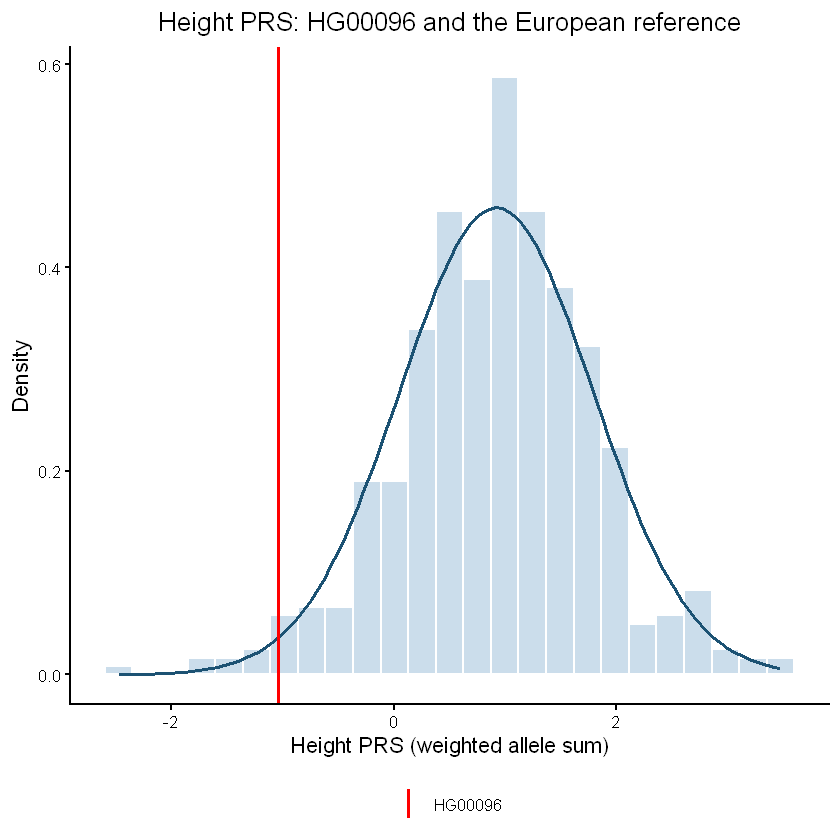

In [9]:
sample_id <- "HG00096"
prs <- run_height_prs(
  tempfile("height-prs-"), sample_id = sample_id, project_root = project_root
)

reference <- data.frame(score = prs$reference_scores)
reference <- reference[is.finite(reference$score), , drop = FALSE]
selected <- data.frame(score = prs$sample_score)
percentile <- 100 * mean(reference$score < prs$sample_score)

p <- ggplot(reference, aes(x = score)) +
  geom_histogram(
    aes(y = after_stat(density)),
    bins = 25,
    fill = "#CBDDEB",
    color = "white"
  ) +
  stat_function(
    fun = dnorm,
    args = list(mean = mean(reference$score), sd = sd(reference$score)),
    color = "#1C5273",
    linewidth = 1
  ) +
  geom_vline(
    data = selected,
    aes(xintercept = score, color = sample_id),
    linewidth = 1
  ) +
  scale_color_manual(name = NULL, values = setNames("red", sample_id)) +
  labs(
    title = paste("Height PRS:", sample_id, "and the European reference"),
    x = "Height PRS (weighted allele sum)",
    y = "Density"
  ) +
  theme_classic(base_size = 13) +
  theme(
    plot.title = element_text(hjust = 0.5),
    legend.position = "bottom"
  )

derived_dir <- file.path(project_root, "data/derived")
dir.create(derived_dir, recursive = TRUE, showWarnings = FALSE)
ggsave(
  filename = file.path(derived_dir, paste0(sample_id, "_height_PRS.png")),
  plot = p,
  width = 10, height = 6, units = "in",
  dpi = 300, bg = "white"
)

cat(sprintf("%s percentile: %.2f\n", sample_id, percentile))
p